<a href="https://colab.research.google.com/github/udamarla1/TimeSeries_Anomaly_Detection_LSTM_Autoencoder_S-P500/blob/main/TimeSeries_Anomaly_Detection_LSTM_Autoencoder_S%26P500.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Step 1: Environment setup and importing libraries
#Step 2: Load S&P DataSet dataset and perform EDA
#Step 3: Chronological data splitting
#Step 4: Feature scaling
#Step 5: Create sliding window sequences
#Step 6: Build LSTM Autoencoder
#Step 7: Train and monitor the model
#Step 8: Calculate reconstruction error
#Step 9: Determine anomaly threshold
#Step 10: Detect and visualize anomalies
#Step 11: Evaluate and improve the model
#Step 12: Save and deploy the model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    RepeatVector,
    Dropout,
    TimeDistributed
)

from sklearn.preprocessing import StandardScaler

In [2]:
print("TensorFlow version:", tf.__version__)

print(
    "GPU available:",
    tf.config.list_physical_devices('GPU')
)

keras.utils.set_random_seed(42)

TensorFlow version: 2.21.0
GPU available: []


In [3]:
from google.colab import drive
import os

drive.mount(os.path.join(os.getcwd(), 'drive'))

Mounted at /content/drive


In [4]:
df = pd.read_csv("/content/drive/MyDrive/dataset/spx.csv")
df.head(10)

,date,close
0,02-Jan-86,209.59
1,03-Jan-86,210.88
2,06-Jan-86,210.65
3,07-Jan-86,213.80
4,08-Jan-86,207.97
5,09-Jan-86,206.11
6,10-Jan-86,205.96
7,13-Jan-86,206.72
8,14-Jan-86,206.64
9,15-Jan-86,208.26


In [5]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

Dataset shape: (8192, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8192 entries, 0 to 8191
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    8192 non-null   object 
 1   close   8192 non-null   float64
dtypes: float64(1), object(1)
memory usage: 128.1+ KB


In [6]:


print("\nStatistical summary:")
display(df.describe())


Statistical summary:


,close
count,8192.000000
mean,1070.897411
std,616.714534
min,203.490000
25%,458.632500
50%,1106.435000
75%,1388.132500
max,2872.870000


In [7]:


print("\nMissing values:")
print(df.isnull().sum())


Missing values:
date     0
close    0
dtype: int64


In [8]:


print("\nDuplicate timestamps:")
print(df.index.duplicated().sum())


Duplicate timestamps:
0


In [9]:


print("\nDate range:")
print(df.index.min())
print(df.index.max())


Date range:
0
8191


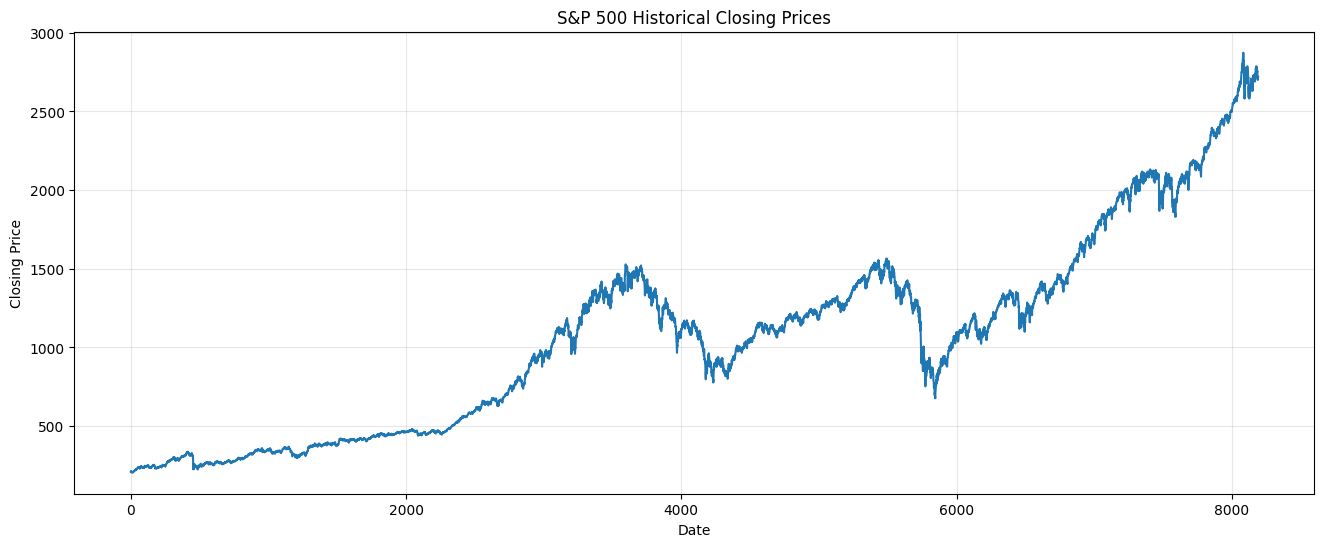

In [10]:
plt.figure(figsize=(16, 6))

plt.plot(df.index, df["close"])

plt.title("S&P 500 Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(alpha=0.3)

plt.show()

In [11]:
df["daily_return"] = df["close"].pct_change()

df["log_return"] = np.log(df["close"]).diff()

df.head()

,date,close,daily_return,log_return
0,02-Jan-86,209.59,NaN,NaN
1,03-Jan-86,210.88,0.006155,0.006136
2,06-Jan-86,210.65,-0.001091,-0.001091
3,07-Jan-86,213.80,0.014954,0.014843
4,08-Jan-86,207.97,-0.027268,-0.027647


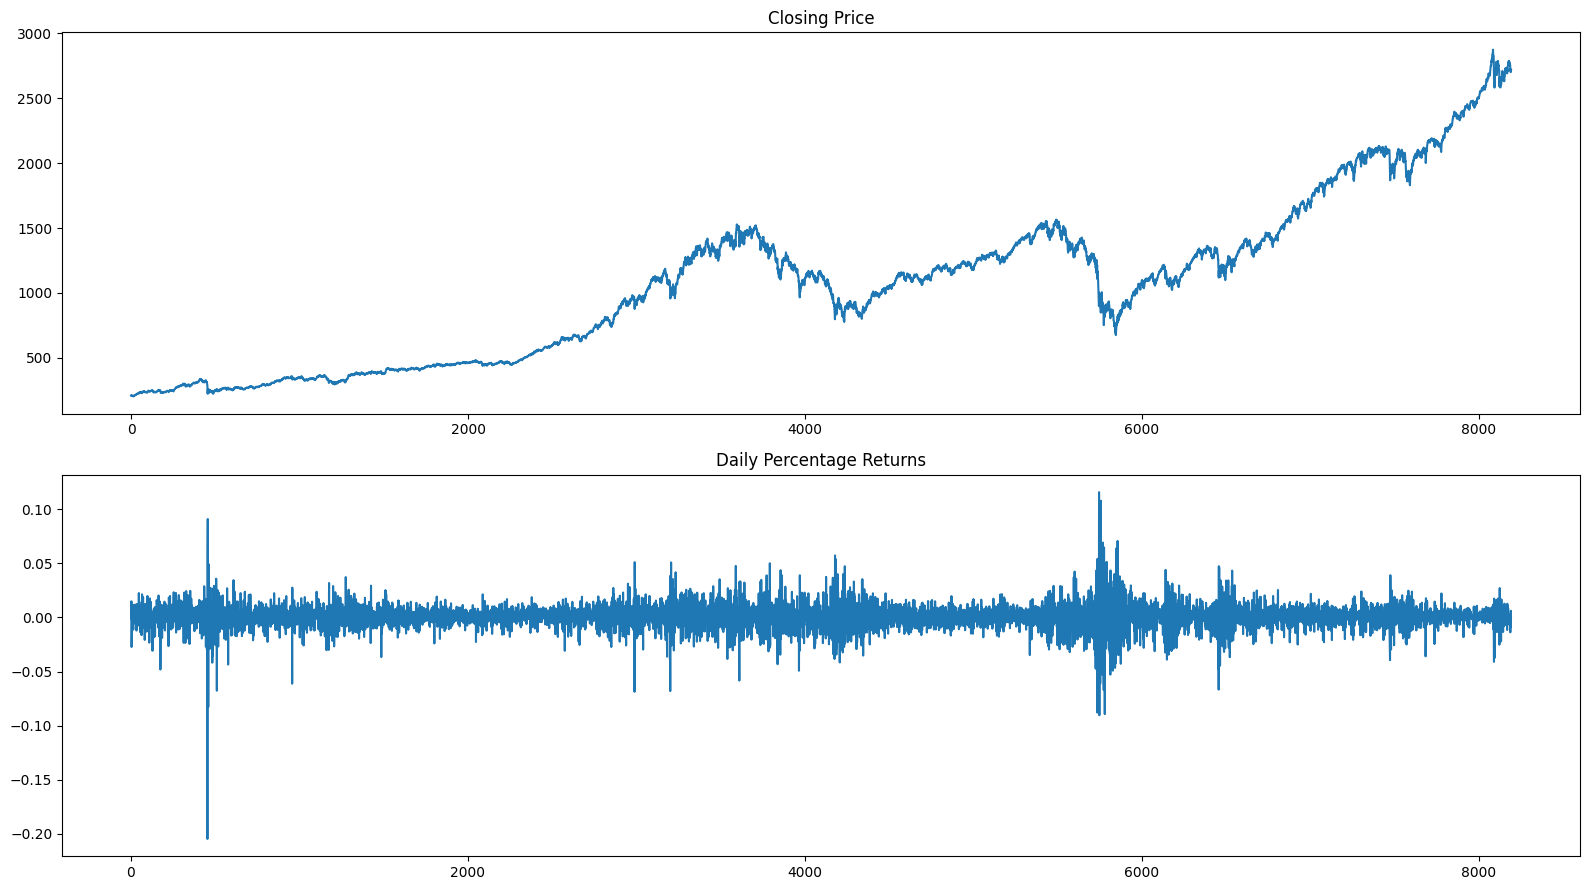

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(16, 9))

df["close"].plot(ax=axes[0])

axes[0].set_title("Closing Price")

df["daily_return"].plot(ax=axes[1])

axes[1].set_title("Daily Percentage Returns")

plt.tight_layout()
plt.show()

In [13]:
data = df[["close"]].copy()

train_end = int(len(data) * 0.8)

val_end = int(len(data) * 0.9)

train_data = data.iloc[:train_end].copy()

In [14]:
val_data = data.iloc[train_end:val_end].copy()

test_data = data.iloc[val_end:].copy()

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)

Training: (6553, 1)
Validation: (819, 1)
Testing: (820, 1)


In [15]:
scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_data)

val_scaled = scaler.transform(val_data)

test_scaled = scaler.transform(test_data)

In [16]:
print("Training mean:", scaler.mean_)

print("Training standard deviation:", scaler.scale_)

print(train_scaled[:5])

Training mean: [842.21062872]
Training standard deviation: [417.2633892]
[[-1.51611822]
 [-1.51302665]
 [-1.51357786]
 [-1.50602867]
 [-1.52000066]]


## Sliding window sequences

In [27]:
TIMESTEPS = 30

def create_sequences(data, timesteps=30):

    sequences = []

    for i in range(len(data) - timesteps + 1):

        sequence = data[i : i + timesteps]

        sequences.append(sequence)

    return np.array(sequences)


In [28]:
sample = np.array([
    [200],
    [202],
    [205],
    [203],
    [207]
])

result = create_sequences(sample, timesteps=3)

print(result)
print(result.shape)

[[[200]
  [202]
  [205]]

 [[202]
  [205]
  [203]]

 [[205]
  [203]
  [207]]]
(3, 3, 1)


In [29]:
X_train = create_sequences(train_scaled, TIMESTEPS)

X_val = create_sequences(val_scaled, TIMESTEPS)

X_test = create_sequences(test_scaled, TIMESTEPS)

print("X_train:", X_train.shape)

print("X_val:", X_val.shape)

print("X_test:", X_test.shape)

X_train: (6524, 30, 1)
X_val: (790, 30, 1)
X_test: (791, 30, 1)


In [30]:
LSTM_UNITS = 64

N_FEATURES = X_train.shape[2]

model = keras.Sequential([

    Input(shape=(TIMESTEPS, N_FEATURES)),

    LSTM(
        LSTM_UNITS,
        return_sequences=False,
        name="encoder_lstm"
    ),

    Dropout(0.2),

    RepeatVector(TIMESTEPS),

    LSTM(
        LSTM_UNITS,
        return_sequences=True,
        name="decoder_lstm"
    ),

    Dropout(0.2),

    TimeDistributed(
        Dense(N_FEATURES)
    )

])

model.compile(
    optimizer="adam",
    loss="mae"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_lstm (LSTM)             │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_lstm (LSTM)             │ (None, 30, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 1)          │            65 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(

    X_train,
    X_train,

    epochs=50,

    batch_size=32,

    validation_data=(X_val, X_val),

    shuffle=False,

    callbacks=[early_stop]

)

Epoch 1/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - loss: 0.1867 - val_loss: 0.5135
Epoch 2/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - loss: 0.1187 - val_loss: 0.6017
Epoch 3/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.1119 - val_loss: 0.5798
Epoch 4/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.1058 - val_loss: 0.6010
Epoch 5/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - loss: 0.1177 - val_loss: 0.6357
Epoch 6/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - loss: 0.1473 - val_loss: 0.8208


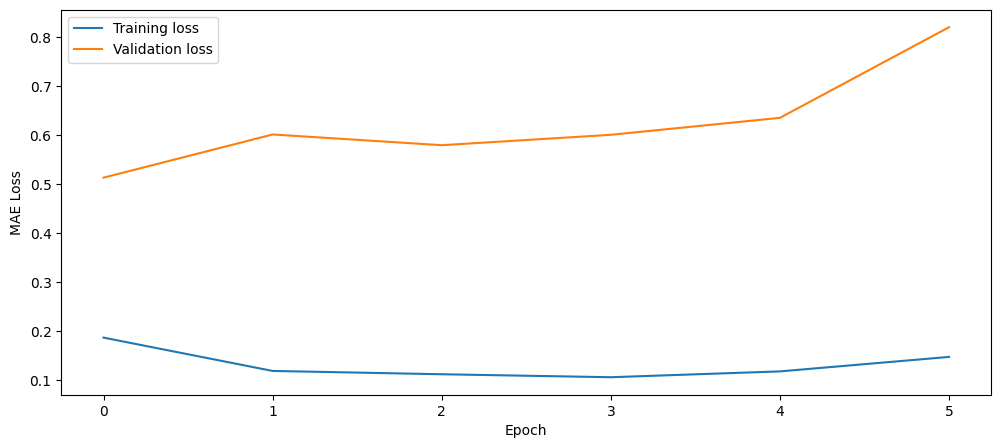

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE Loss")
plt.legend()
plt.show()

In [33]:
train_reconstructed = model.predict(X_train)

print("Original shape:", X_train.shape)

print("Reconstructed shape:",
      train_reconstructed.shape)

204/204 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step
Original shape: (6524, 30, 1)
Reconstructed shape: (6524, 30, 1)


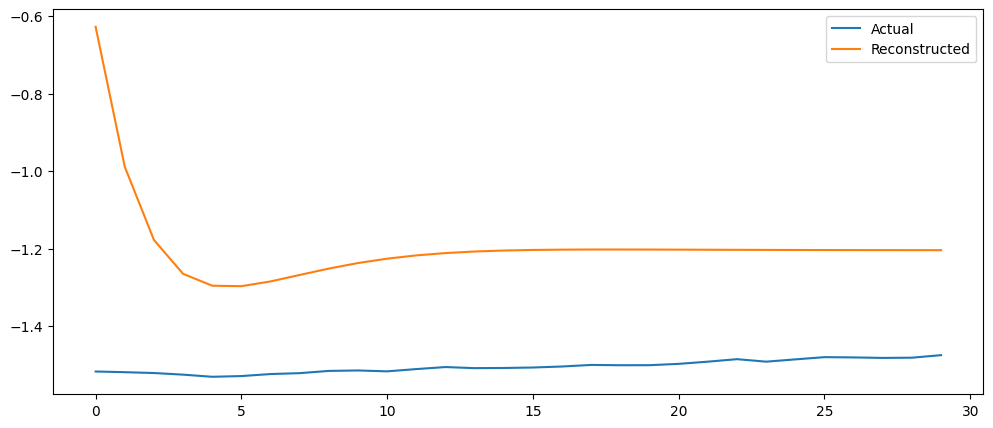

In [34]:
sample_index = 10

plt.figure(figsize=(12, 5))

plt.plot(
    X_train[sample_index, :, 0],
    label="Actual"
)

plt.plot(
    train_reconstructed[sample_index, :, 0],
    label="Reconstructed"
)

plt.legend()
plt.show()

In [35]:
train_mae = np.mean(
    np.abs(X_train - train_reconstructed),
    axis=(1, 2)
)

print(train_mae.shape)

print(train_mae[:10])

(6524,)
[0.30896887 0.30933676 0.31004464 0.31096876 0.3113798  0.31158795
 0.31182853 0.3117203  0.31134088 0.31081082]


In [36]:
val_reconstructed = model.predict(X_val)

val_mae = np.mean(
    np.abs(X_val - val_reconstructed),
    axis=(1, 2)
)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


In [37]:
threshold = np.percentile(val_mae, 99)

print("Anomaly threshold:", threshold)

Anomaly threshold: 1.2135048504122028


In [38]:
test_reconstructed = model.predict(X_test)
test_mae = np.mean(np.abs(X_test - test_reconstructed), axis=(1, 2))

# Create a DataFrame for test anomaly detection results
test_score_df = pd.DataFrame(index=df.index[val_end + TIMESTEPS - 1:])
test_score_df['loss'] = test_mae
test_score_df['threshold'] = threshold
test_score_df['anomaly'] = test_score_df['loss'] > test_score_df['threshold']
test_score_df['close'] = df.iloc[val_end + TIMESTEPS - 1:]['close']

anomalies = test_score_df[test_score_df['anomaly'] == True]
display(anomalies.head())

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


,loss,threshold,anomaly,close
7401,1.230523,1.213505,True,2099.12
7402,1.233075,1.213505,True,2098.48
7403,1.237325,1.213505,True,2121.10
7404,1.240607,1.213505,True,2122.73
7405,1.243225,1.213505,True,2129.20


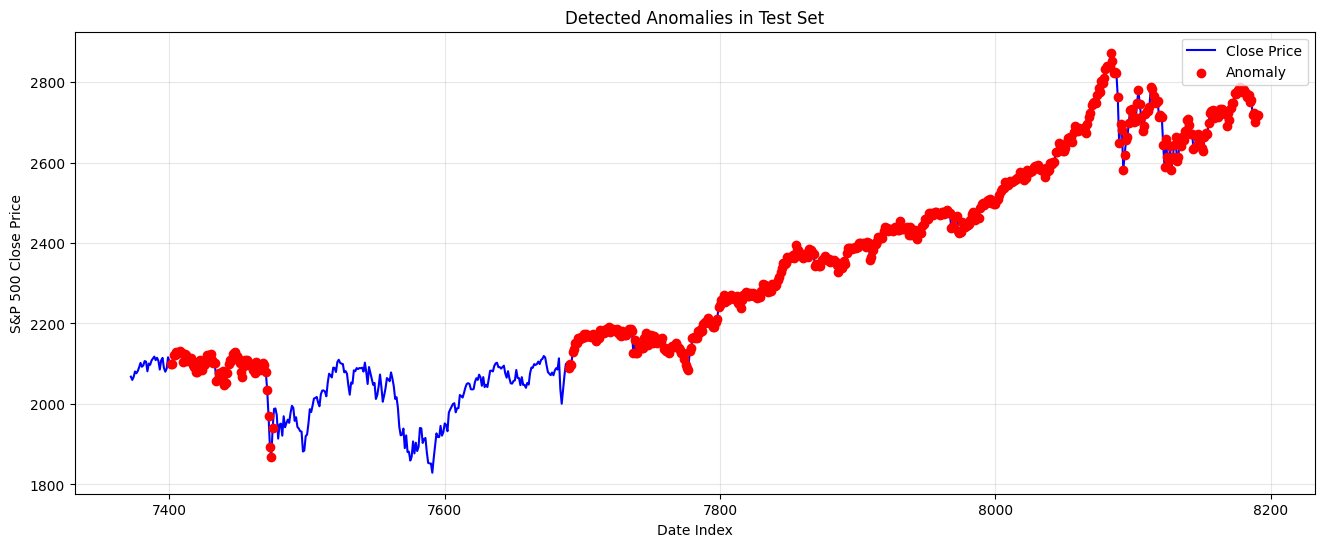

In [39]:
plt.figure(figsize=(16, 6))
plt.plot(df.index[val_end:], df.iloc[val_end:]['close'], label='Close Price', color='blue')
plt.scatter(anomalies.index, anomalies['close'], color='red', label='Anomaly', zorder=5)
plt.title('Detected Anomalies in Test Set')
plt.xlabel('Date Index')
plt.ylabel('S&P 500 Close Price')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

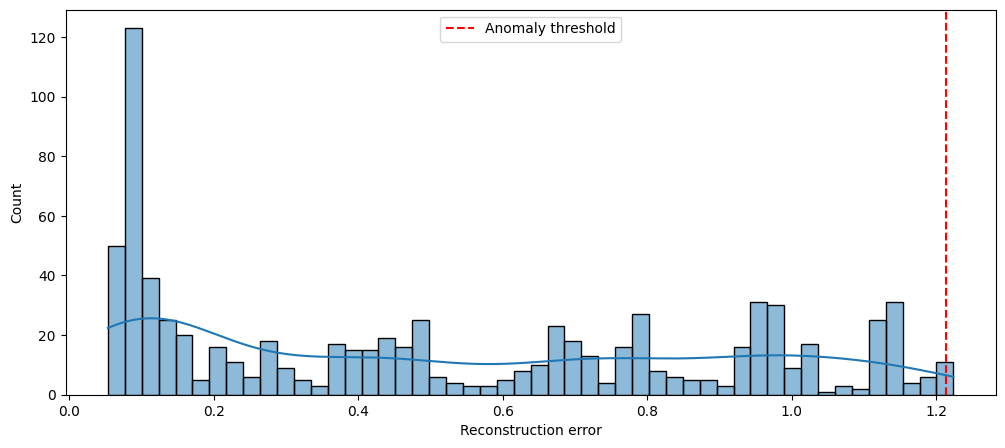

In [40]:
plt.figure(figsize=(12, 5))

sns.histplot(val_mae, bins=50, kde=True)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Anomaly threshold"
)

plt.xlabel("Reconstruction error")
plt.legend()
plt.show()

In [41]:
test_reconstructed = model.predict(X_test)

test_mae = np.mean(
    np.abs(X_test - test_reconstructed),
    axis=(1, 2)
)

y_pred = (test_mae > threshold).astype(int)

print("Total sequences:", len(y_pred))

print("Anomalous sequences:", y_pred.sum())

print("Anomaly percentage:", y_pred.mean() * 100)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Total sequences: 791
Anomalous sequences: 577
Anomaly percentage: 72.9456384323641


In [42]:
results = test_data.iloc[TIMESTEPS - 1:].copy()

results["anomaly_score"] = test_mae

results["threshold"] = threshold

results["anomaly"] = y_pred

results.head()

,close,anomaly_score,threshold,anomaly
7401,2099.12,1.230523,1.213505,1
7402,2098.48,1.233075,1.213505,1
7403,2121.10,1.237325,1.213505,1
7404,2122.73,1.240607,1.213505,1
7405,2129.20,1.243225,1.213505,1


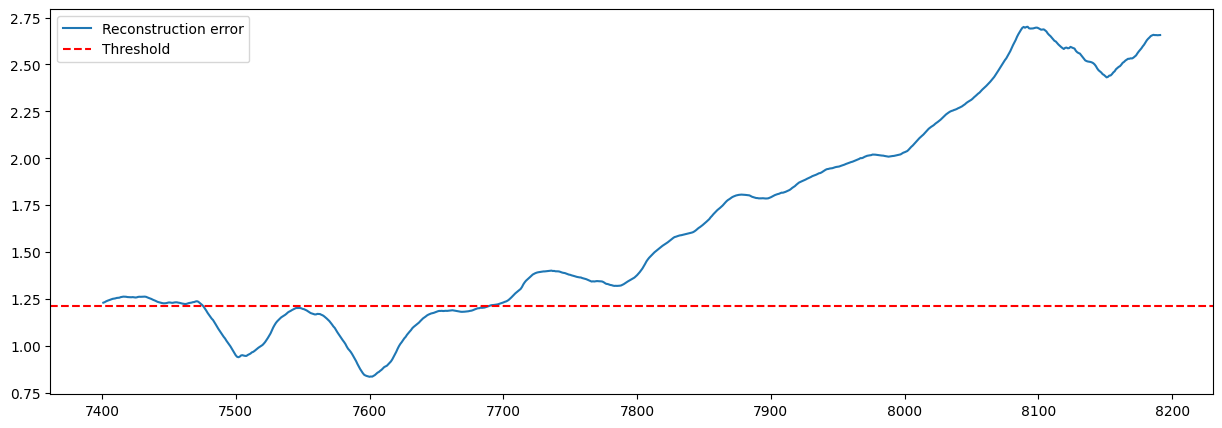

In [43]:
plt.figure(figsize=(15, 5))

plt.plot(
    results.index,
    results["anomaly_score"],
    label="Reconstruction error"
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.legend()
plt.show()

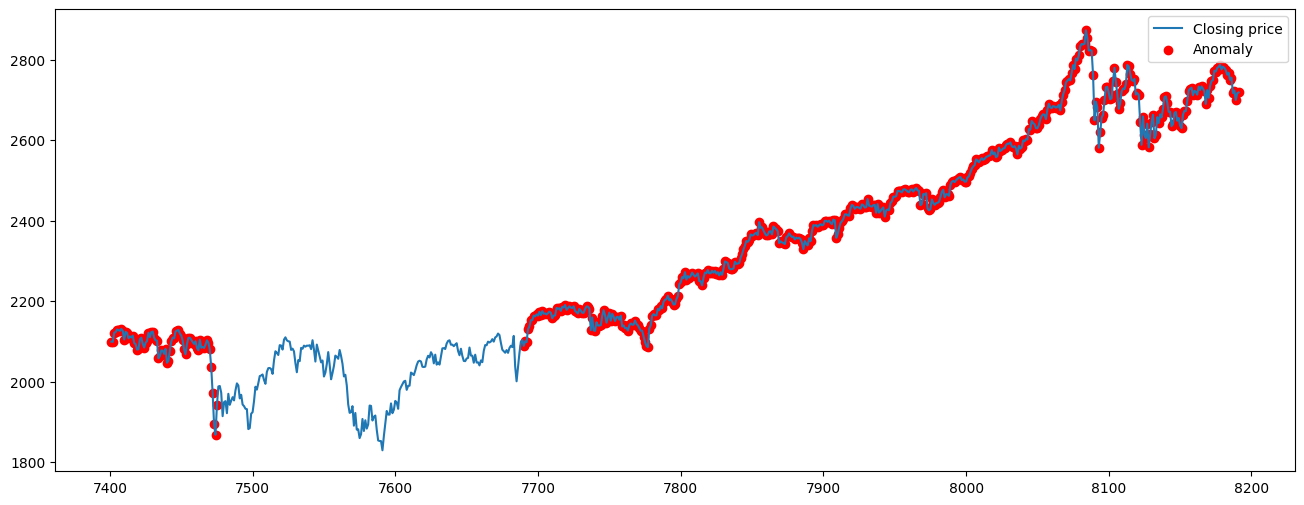

In [44]:
anomalies = results[results["anomaly"] == 1]

plt.figure(figsize=(16, 6))

plt.plot(
    results.index,
    results["close"],
    label="Closing price"
)

plt.scatter(
    anomalies.index,
    anomalies["close"],
    color="red",
    label="Anomaly"
)

plt.legend()
plt.show()